# Defining Your Own Python Function


## 1. Functions
A function groups a task under a name. Calling it runs its body with the supplied arguments. A function may compute a result, interact with its environment, or do both.


For a mathematical analogy, a function can map one or more inputs and a set of outputs.
This concept is typically represented by the following equation:

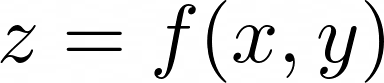

*f()* is a function that operates on the variables x and y, and it generates a result that’s assigned to z. You can read this formula as z is a function of x and y.

Functions are also used in programming. In fact, functions are so fundamental to software development that virtually all modern, mainstream programming languages support them. In programming, a function is a self-contained block of code that encapsulates a specific task under a descriptive name that you can reuse in different places of your code.

Many programming languages have built-in functions, and Python is no exception. For example, Python’s built-in *id()* function takes an object as an argument and returns its unique identifier:

In [2]:
language = "Python"
id(language)

2017174283760

The integer number in this output uniquely identifies the string object you’ve used as an argument. In CPython, this number represents the memory address where the object is stored.

Similarly, the built-in *len()* function takes a data collection as an argument and returns its length:

In [3]:
numbers = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
items = len(numbers)
items

10

Most programming languages allow you to define your own functions. When you define a Python function, you decide whether it takes arguments. You’re also responsible for how the function internally computes its result.

## 2. Why use functions?
| Benefit | Role in a program |
|---|---|
| Abstraction | Expose a meaningful operation without requiring callers to follow its implementation. |
| Encapsulation | Keep local names within a function call's scope. |
| Modularity | Divide a larger workflow into smaller tasks. |
| Reusability | Call one implementation in multiple places. |
| Maintainability | Localize changes and reduce duplicated logic. |
| Testability | Check a task through well-defined inputs and outputs. |

Local scope does not prevent a function from changing a shared mutable object. Later examples distinguish local rebinding from mutation.

In [2]:
label = "outside"

def describe_local_scope():
    label = "inside"
    return label

print("Function's local value:", describe_local_scope())
print("Outer value:", label)

Function's local value: inside
Outer value: outside


### A modular workflow
The following in-memory example separates reading, processing, and formatting. It illustrates the article's read–process–write structure without creating external files.

In [3]:
def read_values(text):
    return [float(part) for part in text.split(",")]

def process_values(values):
    return [value * 2 for value in values]

def format_values(values):
    return ", ".join(f"{value:.1f}" for value in values)

raw_data = "1, 2, 3"
processed_data = process_values(read_values(raw_data))
print(format_values(processed_data))
assert process_values([1, 2]) == [2, 4]

2.0, 4.0, 6.0


## 3. Defining and calling functions
A function definition starts with `def`, followed by an identifier, parentheses, and a colon. Indentation marks the body. Defining the function creates the function object; calling it executes the body.

```python
def function_name(parameter):
    # indented body
    return parameter
```

A **parameter** is a name in the definition; an **argument** is a value supplied in a call.

In [4]:
def greet(name):
    print(f"Hello, {name}!")

greet("Pythonista")

Hello, Pythonista!


### Empty parameter lists, stubs, and function objects
 A `pass` statement provides a valid placeholder body. Writing a function's name without calling it refers to the function object.

In [5]:
def placeholder():
    pass

print("Stub return value:", placeholder())
print("Is greet callable?", callable(greet))
greeting_function = greet
greeting_function("notebook reader")

Stub return value: None
Is greet callable? True
Hello, notebook reader!


## 4. Positional and keyword arguments
### Positional arguments
Python binds ordinary positional arguments to parameters in order. Supplying values in the wrong order can produce an error or, more subtly, a plausible but incorrect result.

In [6]:
def calculate_cost(item, quantity, price):
    print(f"{quantity} {item} cost ${quantity * price:.2f}")

calculate_cost("bananas", 6, 0.74)
calculate_cost("bananas", 0.74, 6)  # Runs, but the quantity is wrong.

6 bananas cost $4.44
0.74 bananas cost $4.44


### Inspecting expected errors
This helper displays an expected exception and verifies its type. It is notebook scaffolding, not a requirement for defining functions.

In [7]:
def show_expected_error(exception_type, operation):
    try:
        operation()
    except exception_type as error:
        print(f"{type(error).__name__}: {error}")
    else:
        raise AssertionError(f"Expected {exception_type.__name__}")

show_expected_error(TypeError, lambda: calculate_cost(6, "bananas", 0.74))
show_expected_error(TypeError, lambda: calculate_cost("bananas", 6))
show_expected_error(TypeError, lambda: calculate_cost("bananas", 6, 0.74, "mango"))

TypeError: can't multiply sequence by non-int of type 'float'
TypeError: calculate_cost() missing 1 required positional argument: 'price'
TypeError: calculate_cost() takes 3 positional arguments but 4 were given


### Keyword arguments
Keyword arguments name the target parameters. This makes calls more explicit and permits a different order for parameters that accept keyword binding. Ordinary positional arguments must appear before explicit keyword arguments. A parameter cannot receive two values in the same call.

In [8]:
calculate_cost(item="bananas", quantity=6, price=0.74)
calculate_cost(price=0.74, quantity=6, item="bananas")
calculate_cost("bananas", quantity=6, price=0.74)

show_expected_error(TypeError, lambda: calculate_cost(item="bananas", quantity=6))
show_expected_error(TypeError, lambda: calculate_cost(item="bananas", quantity=6, cost=0.74))
show_expected_error(TypeError, lambda: calculate_cost("bananas", item="mango", quantity=6, price=0.74))

6 bananas cost $4.44
6 bananas cost $4.44
6 bananas cost $4.44
TypeError: calculate_cost() missing 1 required positional argument: 'price'
TypeError: calculate_cost() got an unexpected keyword argument 'cost'
TypeError: calculate_cost() got multiple values for argument 'item'


Invalid syntax cannot be placed directly in a runnable cell. Compiling a string lets us demonstrate the syntax error safely.

In [9]:
invalid_call = 'calculate_cost(item="bananas", quantity=6, 0.74)'
show_expected_error(SyntaxError, lambda: compile(invalid_call, "<example>", "exec"))

SyntaxError: positional argument follows keyword argument (<example>, line 1)


## 5. Side effects and return values
Printing is a side effect: it changes what is displayed. Mutating an argument also changes something visible to the caller. A return value, by contrast, passes an object back for the caller to use.

These are separate mechanisms. A function can both produce side effects and return a value.

In [10]:
def double_in_place(numbers):
    for index, number in enumerate(numbers):
        numbers[index] = number * 2

numbers = [1, 2, 3, 4, 5]
returned = double_in_place(numbers)
print("Mutated input:", numbers)
print("Return value:", returned)

Mutated input: [2, 4, 6, 8, 10]
Return value: None


### Returning a new object
Creating a new list avoids changing the caller's list in this example. The caller chooses whether to keep the result.

In [7]:
def double(numbers):
    result = []
    for number in numbers:
        result.append(number * 2) 
    return result

numbers = [1, 2, 3, 4, 5]
doubled = double(numbers)
print("Original:", numbers)
print("Result:", doubled)
print( numbers == [1, 2, 3, 4, 5])
print(doubled == [2, 4, 6, 8, 10])
print(doubled is not numbers)

Original: [1, 2, 3, 4, 5]
Result: [2, 4, 6, 8, 10]
True
True
True


In [12]:
def double(numbers):
    return [number * 2 for number in numbers]

print(double([2, 4, 6]))

[4, 8, 12]


### Rebinding is not mutation
Assigning a new object to a parameter changes the local binding, not the caller's binding. Mutating the object referred to by a parameter is different. A `global` declaration concerns a named module-level variable; it is not a general mechanism for assigning back to the caller's argument.

In [13]:
def replace_locally(values):
    values = [99]
    return values

original = [1, 2, 3]
replacement = replace_locally(original)
print("Caller list:", original)
print("Locally created replacement:", replacement)

Caller list: [1, 2, 3]
Locally created replacement: [99]


### Returning one or several values
`return` ends the current function call and supplies its value to the caller. Comma-separated return expressions produce one tuple, which the caller may unpack.

In [14]:
def identity(value):
    return value

def create_point(x, y):
    return x, y

def as_dict():
    return {"one": 1, "two": 2, "three": 3}

print(identity(42))
point = create_point(2, 4)
x, y = point
print("Point:", point)
print("Unpacked coordinates:", x, y)
print("Dictionary lookup:", as_dict()["two"])

42
Point: (2, 4)
Unpacked coordinates: 2 4
Dictionary lookup: 2


### Returning `None`
A bare `return`, an explicit `return None`, and reaching the end of a normal function all produce `None`. Use `is None` or `is not None` when you specifically mean absence, rather than any false-valued object.

In [15]:
def bare_return():
    return

def implicit_return():
    pass

def find_user(username, user_list):
    for user in user_list:
        if user["username"] == username:
            return user
    return None

users = [
    {"username": "alice", "email": "alice@example.com"},
    {"username": "bob", "email": "bob@example.com"},
]
print("Bare return:", bare_return())
print("Implicit return:", implicit_return())
print("Found:", find_user("alice", users))
print("Not found:", find_user("linda", users))
if find_user("linda", users) is None:
    print("Linda is not a registered user.")

Bare return: None
Implicit return: None
Found: {'username': 'alice', 'email': 'alice@example.com'}
Not found: None
Linda is not a registered user.


## 6. Early exits and predicates
### Guard clauses
An early `return` can stop a function when a prerequisite fails. This file-reading example uses a temporary directory so the demonstration does not leave files behind.

The checks are illustrative, not comprehensive file-error handling: permissions, decoding errors, or a change to the file between checking and reading can still cause exceptions.

In [16]:
from pathlib import Path
from tempfile import TemporaryDirectory

def read_file_contents(file_path):
    path = Path(file_path)
    if not path.exists():
        print(f"Error: The file '{path.name}' does not exist.")
        return
    if not path.is_file():
        print(f"Error: '{path.name}' is not a file.")
        return
    return path.read_text(encoding="utf-8")

with TemporaryDirectory() as directory:
    root = Path(directory)
    sample = root / "sample.txt"
    sample.write_text("Functions make tasks reusable.", encoding="utf-8")
    print(read_file_contents(sample))
    print("Missing-file result:", read_file_contents(root / "missing.txt"))
    print("Directory result:", read_file_contents(root))

Functions make tasks reusable.
Error: The file 'missing.txt' does not exist.
Missing-file result: None
Error: 'tmplulrmw9t' is not a file.
Directory result: None


### Boolean-valued functions
A predicate answers a question with `True` or `False`. Returning the comparison directly avoids an unnecessary `if`/`else`.

In [17]:
def is_even(number):
    return number % 2 == 0

print("2 is even:", is_even(2))
print("3 is even:", is_even(3))
print("Even values:", [number for number in range(8) if is_even(number)])
assert is_even(0) is True

2 is even: True
3 is even: False
Even values: [0, 2, 4, 6]


## 7. Generator functions
A function containing `yield` creates a generator iterator when called. Iteration resumes its body and obtains values one at a time. Unlike a normal `return`, `yield` suspends execution while preserving local state.

Generator iterators are objects that allow you to iterate over a stream of data or large datasets without storing the entire dataset in memory at once.

The running-average generator does not store every computed average. Total memory use still depends on the input and on whether the caller collects the outputs.

In [18]:
def cumulative_average(numbers):
    total = 0
    for count, number in enumerate(numbers, start=1):
        total += number
        yield total / count

values = [5, 3, 8, 2, 5]
for average in cumulative_average(values):
    print(f"Cumulative average: {average:.2f}")

Cumulative average: 5.00
Cumulative average: 4.00
Cumulative average: 5.33
Cumulative average: 4.50
Cumulative average: 4.60


A generator iterator is consumed as it is advanced. Create a new iterator to start again. Turning it into a list is convenient for inspection, but stores its remaining outputs.

These functions are handy when you’re working with large datasets and aiming to make your code more memory-efficient. 

In [19]:
averages = cumulative_average(values)
print("First:", next(averages))
print("Second:", next(averages))
print("Remaining:", list(averages))
print("After exhaustion:", list(averages))
assert list(cumulative_average([])) == []

First: 5.0
Second: 4.0
Remaining: [5.333333333333333, 4.5, 4.6]
After exhaustion: []


## 8. Closures
A nested function can retain access to bindings from an enclosing function after the outer call has finished. Returning the nested function object—not calling it immediately—lets the caller use that closure later.

In [20]:
def make_revealer():
    value = 42
    def reveal():
        print(f"The value is: {value}!")
    return reveal

reveal_number = make_revealer()
reveal_number()

The value is: 42!


In [21]:
def generate_power(exponent):
    def power(base):
        return base ** exponent
    return power

square = generate_power(2)
cube = generate_power(3)
print("square(4):", square(4))
print("square(6):", square(6))
print("cube(3):", cube(3))
print("cube(5):", cube(5))
assert square(5) == 25
assert cube(5) == 125

square(4): 16
square(6): 36
cube(3): 27
cube(5): 125


Closures have several use cases. You can use closures to create stateful functions, callbacks, decorators, factory functions, and more.

More on closures and inner function in the next lectures

## 9. Default argument values
A default value makes a parameter optional for the caller. The supplied argument overrides the default. In the ordinary parameter list, required parameters must precede parameters with defaults.

In [22]:
def greet(name, verbose=False):
    if verbose:
        return f"Hello, {name}! It is a pleasure to meet you."
    return f"Hello, {name}!"

print(greet("Pythonista"))
print(greet("Pythonista", verbose=True))

Hello, Pythonista!
Hello, Pythonista! It is a pleasure to meet you.


### Supplementary demonstration: mutable defaults
Default expressions are evaluated when the function definition executes, not afresh for every call. A list used as a default can therefore accumulate changes across calls. 

Use `None` and create a list inside the function when each omitted argument should get a fresh list.

In [8]:
def append_shared(item, items=[]):
    items.append(item)
    return items

print("First call:", append_shared("a"))
print("Second call:", append_shared("b"))

def append_fresh(item, items=None):
    if items is None:
        items = []
    items.append(item)
    return items

print("Fresh first call:", append_fresh("a"))
print("Fresh second call:", append_fresh("b"))
existing = ["start"]
print("Explicit list:", append_fresh("end", existing))

First call: ['a']
Second call: ['a', 'b']
Fresh first call: ['a']
Fresh second call: ['b']
Explicit list: ['start', 'end']


## 10. Variable-length argument lists
### Collecting positional arguments with `*args`
A starred parameter collects additional positional arguments in a **tuple**. 

The name `args` is conventional; the `*` provides the behavior.

In [24]:
def total(*numbers):
    print("Collected positional arguments:", numbers)
    return sum(numbers)

print("Total:", total(2, 3, 5))
print("Empty total:", total())

Collected positional arguments: (2, 3, 5)
Total: 10
Collected positional arguments: ()
Empty total: 0


### Collecting keyword arguments with `**kwargs`

`**kwargs` syntax that lets you pass an arbitrary number of keyword arguments to a function.

Placing a double asterisk (**) before a parameter name in a function definition tells Python to pack the provided keyword arguments into a dictionary.

The name `kwargs` is also conventional.

In [25]:
def describe_person(name, **details):
    return {"name": name, **details}

print(describe_person("Alice", role="researcher", language="Python"))

{'name': 'Alice', 'role': 'researcher', 'language': 'Python'}


Here’s a practical example of using **kwargs. Say you want to write a function that builds a report, but you don’t always know ahead of time which fields will be passed:

In [9]:
def report(**kwargs):
    print("Report:")
    for key, value in kwargs.items():
        print(f" - {key.capitalize()}: {value}")


report(name="Keyboard", price=19.99, quantity=5, category="PC Components")

Report:
 - Name: Keyboard
 - Price: 19.99
 - Quantity: 5
 - Category: PC Components


### Unpacking arguments at the call site
In a definition, `*` and `**` collect arguments. In a call, they unpack an iterable or mapping into arguments.

In [26]:
def multiply(a, b, c):
    return a * b * c

values_to_multiply = [2, 3, 4]
named_values = {"a": 2, "b": 3, "c": 4}
print("Unpacked positional values:", multiply(*values_to_multiply))
print("Unpacked keyword values:", multiply(**named_values))

Unpacked positional values: 24
Unpacked keyword values: 24


## 11. Keyword-only and positional-only parameters
Parameters after `*` or `*args` are keyword-only. Parameters before `/` are positional-only. Parameters between `/` and `*` can normally be passed either way.

The `/` function-definition syntax requires Python 3.8 or later. These markers describe calling constraints, not data types.

In [14]:
def format_name(first_name, last_name, /, title=None):
    full_name = f"{first_name} {last_name}"
    if title is not None:
        full_name = f"{title} {full_name}"
    return full_name


# Correct calls
print(format_name("Jane", "Doe"))

print(format_name("John", "Doe", title="Dr."))

print(format_name("Linda", "Brown", "PhD."))


# Incorrect calls
print(format_name("John", last_name="Doe", title="Dr."))

Jane Doe
Dr. John Doe
PhD. Linda Brown


TypeError: format_name() got some positional-only arguments passed as keyword arguments: 'last_name'

In [11]:
def calculate(x, y, *, operator):
    if operator == "+":
        return x + y
    elif operator == "-":
        return x - y
    elif operator == "*":
        return x * y
    elif operator == "/":
        return x / y
    else:
        raise ValueError("invalid operator")


print(calculate(3, 4, operator="+"))

print(calculate(3, 4, operator="-"))

print(calculate(3, 4, operator="*"))

print(calculate(3, 4, operator="/"))

# Incorrect calls
print(calculate(3, 4, "+"))

7
-1
12
0.75


TypeError: calculate() takes 2 positional arguments but 3 were given

### Combining parameter kinds
Read this signature from left to right: a positional-only name, an ordinary parameter with a default, extra positional values, a keyword-only option, and extra keyword values.

In [15]:
def inspect_arguments(name, /, count=1, *items, verbose=False, **metadata):
    return {
        "name": name,
        "count": count,
        "items": items,
        "verbose": verbose,
        "metadata": metadata,
    }

print(inspect_arguments("sample", 2, "a", "b", verbose=True, source="notebook"))

{'name': 'sample', 'count': 2, 'items': ('a', 'b'), 'verbose': True, 'metadata': {'source': 'notebook'}}


## 12. Docstrings and annotations
### Docstrings
A string literal placed first in the function body becomes its docstring. Explain the task, inputs, outputs, and relevant errors. Runtime tools such as `help()` and `__doc__` expose this documentation.

In [29]:
def rectangle_area(width, height):
    """Return the area of a rectangle with nonnegative dimensions.

    Args:
        width: Rectangle width.
        height: Rectangle height.

    Returns:
        The product of width and height.

    Raises:
        ValueError: If either dimension is negative.
    """
    if width < 0 or height < 0:
        raise ValueError("Dimensions must be nonnegative")
    return width * height

print(rectangle_area.__doc__)
print("Area:", rectangle_area(3, 4))
show_expected_error(ValueError, lambda: rectangle_area(-3, 4))

Return the area of a rectangle with nonnegative dimensions.

    Args:
        width: Rectangle width.
        height: Rectangle height.

    Returns:
        The product of width and height.

    Raises:
        ValueError: If either dimension is negative.
    
Area: 12
ValueError: Dimensions must be nonnegative


### Type annotations
Annotations communicate intended types to readers and tools. A parameter annotation follows `:`, and a return annotation follows `->`. Python does not automatically enforce these type hints when the function is called; checks in the body and external type-checking tools have different roles.

In [30]:
def add_numbers(left: int, right: int) -> int:
    """Return the sum of two intended integer inputs."""
    return left + right

print("Integer inputs:", add_numbers(2, 3))
print("String inputs still execute:", add_numbers("Py", "thon"))

import inspect
print("Signature:", inspect.signature(add_numbers))
print("Annotated parameter names:", list(add_numbers.__annotations__))

Integer inputs: 5
String inputs still execute: Python
Signature: (left: int, right: int) -> int
Annotated parameter names: ['left', 'right', 'return']


## Summary
| Concept | Syntax or pattern |
|---|---|
| Define a function | `def task(parameter):` followed by an indented body |
| Call a function | `task(argument)` |
| Supply a named argument | `task(parameter=value)` |
| Return an object | `return result` |
| Return a tuple | `return first, second` |
| Default parameter value | `def task(option=False):` |
| Extra positional arguments | `def task(*args):` |
| Extra keyword arguments | `def task(**kwargs):` |
| Keyword-only parameter | `def task(*, option):` |
| Positional-only parameter | `def task(value, /):` |
| Generator function | Use `yield` in the function body |
| Closure | Return a nested function that uses an enclosing binding |
| Documentation | Put a docstring first in the function body |
| Type hints | `def task(value: int) -> int:` |

